In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# DECISION THEORY USING PYTHON
# Comparing Maximin, Maximax, Hurwicz and Minimax Regret
# 1. Define the payoff matrix
payoff = np.array([
    [15, 12, 18],   # a1
    [9,  14, 10],   # a2
    [13, 4,  26]    # a3
], dtype=float)

acts = ["a1", "a2", "a3"]
states = ["θ1", "θ2", "θ3"]

payoff_df = pd.DataFrame(
    payoff,
    index=acts,
    columns=states
)

In [3]:
print("\nPAYOFF MATRIX")
print(payoff_df)


PAYOFF MATRIX
      θ1    θ2    θ3
a1  15.0  12.0  18.0
a2   9.0  14.0  10.0
a3  13.0   4.0  26.0


In [4]:
# 2. MAXIMIN CRITERION
row_min = payoff.min(axis=1)

maximin_value = row_min.max()
maximin_act = acts[row_min.argmax()]

print("\nMAXIMIN CRITERION")
for act, value in zip(acts, row_min):
    print(f"{act}: {value:g}")

print(f"Selected strategy: {maximin_act}")
print(f"Maximin value: {maximin_value:g}")


MAXIMIN CRITERION
a1: 12
a2: 9
a3: 4
Selected strategy: a1
Maximin value: 12


In [5]:
# 3. MAXIMAX CRITERION
row_max = payoff.max(axis=1)

maximax_value = row_max.max()
maximax_act = acts[row_max.argmax()]

print("\nMAXIMAX CRITERION")
for act, value in zip(acts, row_max):
    print(f"{act}: {value:g}")

print(f"Selected strategy: {maximax_act}")
print(f"Maximax value: {maximax_value:g}")


MAXIMAX CRITERION
a1: 18
a2: 14
a3: 26
Selected strategy: a3
Maximax value: 26


In [6]:
# 4. HURWICZ CRITERION
alpha = 0.60

hurwicz_values = (
    (1 - alpha) * row_min
    + alpha * row_max
)

hurwicz_value = hurwicz_values.max()
hurwicz_act = acts[hurwicz_values.argmax()]

print("\nHURWICZ CRITERION")
print(f"Coefficient of optimism (alpha): {alpha}")

for act, value in zip(acts, hurwicz_values):
    print(f"{act}: {value:.1f}")

print(f"Selected strategy: {hurwicz_act}")
print(f"Hurwicz value: {hurwicz_value:.1f}")


HURWICZ CRITERION
Coefficient of optimism (alpha): 0.6
a1: 15.6
a2: 12.0
a3: 17.2
Selected strategy: a3
Hurwicz value: 17.2


In [7]:
# 5. MINIMAX REGRET CRITERION
best_by_state = payoff.max(axis=0)

regret = best_by_state - payoff

regret_df = pd.DataFrame(
    regret,
    index=acts,
    columns=states
)

max_regret = regret.max(axis=1)

minimax_regret_value = max_regret.min()
minimax_regret_act = acts[max_regret.argmin()]

print("\nREGRET MATRIX")
print(regret_df)

print("\nMINIMAX REGRET CRITERION")
for act, value in zip(acts, max_regret):
    print(f"{act}: {value:g}")

print(f"Selected strategy: {minimax_regret_act}")
print(f"Minimum maximum regret: {minimax_regret_value:g}")


REGRET MATRIX
     θ1    θ2    θ3
a1  0.0   2.0   8.0
a2  6.0   0.0  16.0
a3  2.0  10.0   0.0

MINIMAX REGRET CRITERION
a1: 8
a2: 16
a3: 10
Selected strategy: a1
Minimum maximum regret: 8


In [8]:
# 6. SUMMARY TABLE
summary = pd.DataFrame({
    "Criterion": [
        "Maximin",
        "Maximax",
        "Hurwicz",
        "Minimax Regret"
    ],
    "Selected Strategy": [
        maximin_act,
        maximax_act,
        hurwicz_act,
        minimax_regret_act
    ],
    "Decision Value": [
        maximin_value,
        maximax_value,
        hurwicz_value,
        minimax_regret_value
    ]
})

print("\nSUMMARY OF DECISION CRITERIA")
print(summary.to_string(index=False))


SUMMARY OF DECISION CRITERIA
     Criterion Selected Strategy  Decision Value
       Maximin                a1            12.0
       Maximax                a3            26.0
       Hurwicz                a3            17.2
Minimax Regret                a1             8.0


In [9]:
# Save summary table
summary.to_csv("decision_theory_summary.csv", index=False)

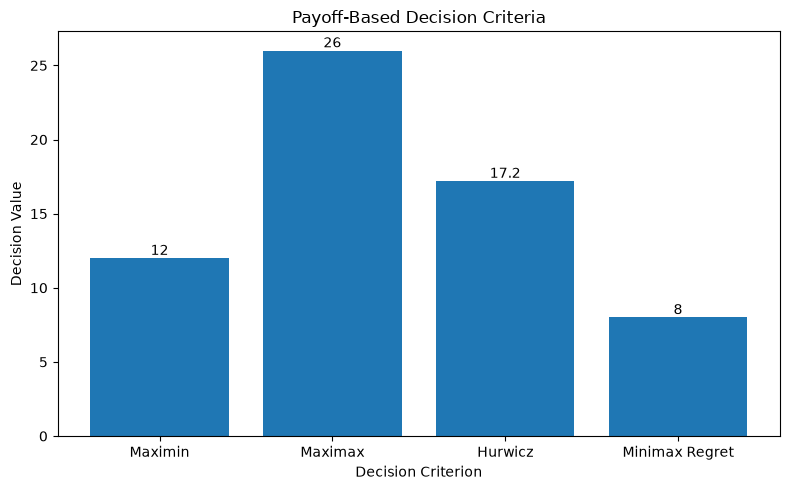

In [13]:
# 7. VISUALIZATION 1:
# Payoff-based criteria
payoff_criteria = ["Maximin", "Maximax", "Hurwicz","Minimax Regret"]
payoff_values = [
    maximin_value,
    maximax_value,
    hurwicz_value,
    minimax_regret_value
]

plt.figure(figsize=(8, 5))
bars = plt.bar(payoff_criteria, payoff_values)

plt.title("Payoff-Based Decision Criteria")
plt.xlabel("Decision Criterion")
plt.ylabel("Decision Value")

for bar, value in zip(bars, payoff_values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value,
        f"{value:g}",
        ha="center",
        va="bottom"
    )
plt.tight_layout()
plt.savefig("payoff_based_criteria.png", dpi=300, bbox_inches="tight")
plt.show()

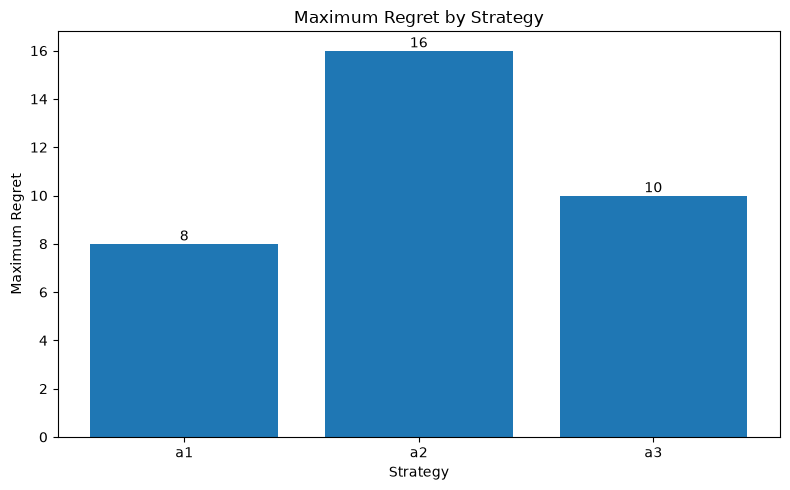

In [16]:
# 8. VISUALIZATION 2:
# Maximum regret by strategy

plt.figure(figsize=(8, 5))
bars = plt.bar(acts, max_regret)

plt.title("Maximum Regret by Strategy")
plt.xlabel("Strategy")
plt.ylabel("Maximum Regret")

for bar, value in zip(bars, max_regret):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value,
        f"{value:g}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.savefig("maximum_regret.png", dpi=300, bbox_inches="tight")
plt.show()

In [15]:
print("\nINTERPRETATION")
print(
    f"Maximin selects {maximin_act} because it has the highest worst-case payoff."
)
print(
    f"Maximax selects {maximax_act} because it has the highest possible payoff."
)
print(
    f"Hurwicz selects {hurwicz_act} when the coefficient of optimism is {alpha:.2f}."
)
print(
    f"Minimax Regret selects {minimax_regret_act} because it has the smallest maximum regret."
)

print("\nProject completed successfully.")


INTERPRETATION
Maximin selects a1 because it has the highest worst-case payoff.
Maximax selects a3 because it has the highest possible payoff.
Hurwicz selects a3 when the coefficient of optimism is 0.60.
Minimax Regret selects a1 because it has the smallest maximum regret.

Project completed successfully.
